# 9. Generative Adversarial Networks with PyTorch

Generative adversarial networks consist of two competing neural networks:

- The **generator** maps random latent vectors to synthetic samples.
- The **discriminator** distinguishes real samples from generated samples.

The generator improves by learning to fool the discriminator, while the discriminator improves by learning to identify generated samples. This notebook first trains a small GAN on a two-dimensional sine distribution and then trains a convolutional GAN to generate handwritten MNIST digits.

All data loading, models, losses, optimization, checkpointing, and inference in this notebook use PyTorch and Torchvision.

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
from torchvision.utils import make_grid
from tqdm.auto import tqdm

SEED = 111
torch.manual_seed(SEED)

In [ ]:
# Select exactly one compute device. CPU is the default.
device = torch.device('cpu')

# macOS with Apple Silicon:
# device = torch.device('mps')

# Windows/Linux with a CUDA-capable NVIDIA GPU
# (change 0 to select another GPU):
# device = torch.device('cuda:0')

print(f'Using device: {device}')

Using device: cuda:0


The discriminator outputs **logits**, not probabilities. We therefore use `BCEWithLogitsLoss`, which combines sigmoid and binary cross-entropy in a numerically stable operation.

The helper functions below temporarily freeze either network during its opponent's update and save both model state dictionaries together with their history and configuration.

In [3]:
MODEL_DIR = Path.cwd() / 'trained_models'


def set_requires_grad(model, requires_grad):
    for parameter in model.parameters():
        parameter.requires_grad = requires_grad


def save_gan_checkpoint(filename, generator, discriminator, history, config):
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
    torch.save(
        {
            'generator_state_dict': generator.state_dict(),
            'discriminator_state_dict': discriminator.state_dict(),
            'history': history,
            'config': config,
        },
        MODEL_DIR / filename,
    )


def load_gan_checkpoint(filename, generator, discriminator):
    checkpoint = torch.load(
        MODEL_DIR / filename, map_location=device, weights_only=True
    )
    generator.load_state_dict(checkpoint['generator_state_dict'])
    discriminator.load_state_dict(checkpoint['discriminator_state_dict'])
    generator.to(device).eval()
    discriminator.to(device).eval()
    return checkpoint['history'], checkpoint['config']

# 1. Learning a sine distribution

The real dataset contains pairs $(x, \sin(x))$ with $x \in [0, 2\pi]$. We normalize the coordinate to $u \in [-1, 1]$, where $x = \pi(u + 1)$.

Instead of asking an unconditional GAN to discover both the position and the curve at once, this section uses a **conditional GAN**. The generator receives a chosen coordinate $u$ together with noise and predicts $y$. The discriminator judges the pair $(u, y)$. Because the mapping is deterministic, an additional L1 reconstruction term gives the generator a direct signal to follow the correct curve while the adversarial loss encourages realistic pairs.

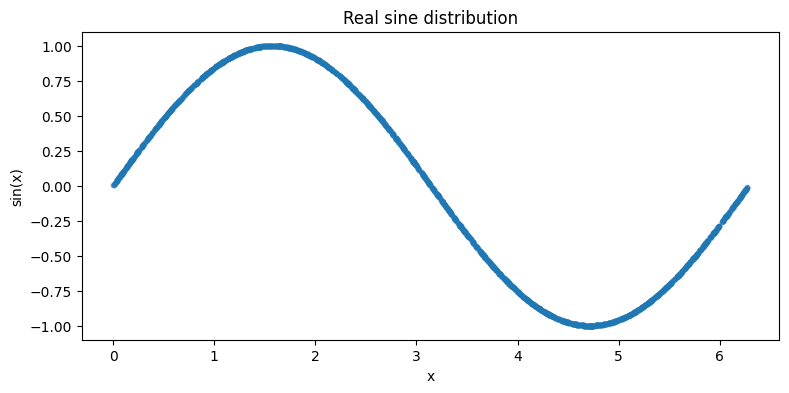

In [4]:
SINE_SAMPLE_COUNT = 2048
SINE_BATCH_SIZE = 128

normalized_x = 2 * torch.rand(SINE_SAMPLE_COUNT, 1) - 1
original_x = math.pi * (normalized_x + 1)
sine_y = torch.sin(original_x)
sine_samples = torch.cat((normalized_x, sine_y), dim=1)

sine_dataset = TensorDataset(normalized_x, sine_y)
sine_loader = DataLoader(
    sine_dataset,
    batch_size=SINE_BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

plt.figure(figsize=(9, 4))
plt.scatter(original_x, sine_y, s=10, alpha=0.5)
plt.xlabel('x')
plt.ylabel('sin(x)')
plt.title('Real sine distribution')
plt.show()

## Sine generator and discriminator

The generator maps a normalized coordinate and a small noise vector to one y-value. The discriminator receives a complete `(u, y)` pair and returns one logit. Neither network uses batch normalization or dropout, so training and evaluation have the same behavior.

In [5]:
class SineGenerator(nn.Module):
    def __init__(self, noise_dim=4):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(1 + noise_dim, 64),
            nn.LeakyReLU(0.2),
            nn.Linear(64, 64),
            nn.LeakyReLU(0.2),
            nn.Linear(64, 1),
            nn.Tanh(),
        )

    def forward(self, normalized_x, noise):
        generator_input = torch.cat((normalized_x, noise), dim=1)
        return self.model(generator_input)


class SineDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(2, 128),
            nn.LeakyReLU(0.2),
            nn.Linear(128, 64),
            nn.LeakyReLU(0.2),
            nn.Linear(64, 1),
        )

    def forward(self, normalized_x, y_values):
        pairs = torch.cat((normalized_x, y_values), dim=1)
        return self.model(pairs)

In [6]:
SINE_NOISE_DIM = 4
SINE_EPOCHS = 300
SINE_LEARNING_RATE = 2e-4
SINE_RECONSTRUCTION_WEIGHT = 10.0

sine_generator = SineGenerator(SINE_NOISE_DIM).to(device)
sine_discriminator = SineDiscriminator().to(device)

sine_loss_fn = nn.BCEWithLogitsLoss()
sine_optimizer_g = torch.optim.Adam(
    sine_generator.parameters(),
    lr=SINE_LEARNING_RATE,
    betas=(0.5, 0.999),
)
sine_optimizer_d = torch.optim.Adam(
    sine_discriminator.parameters(),
    lr=SINE_LEARNING_RATE,
    betas=(0.5, 0.999),
)

fixed_sine_x = torch.linspace(-1, 1, 256, device=device).unsqueeze(1)
fixed_sine_noise = torch.zeros(
    len(fixed_sine_x), SINE_NOISE_DIM, device=device
)

In [7]:
def sample_sine_generator(generator, normalized_x, noise):
    was_training = generator.training
    generator.eval()
    with torch.inference_mode():
        generated_y = generator(normalized_x, noise).cpu()
    generator.train(was_training)
    return torch.cat((normalized_x.cpu(), generated_y), dim=1)


def plot_sine_distribution(real_samples, generated_samples):
    real_samples = real_samples.detach().cpu()
    generated_samples = generated_samples.detach().cpu()

    real_x = math.pi * (real_samples[:, 0] + 1)
    generated_x = math.pi * (generated_samples[:, 0] + 1)

    plt.figure(figsize=(9, 4))
    plt.scatter(
        real_x, real_samples[:, 1],
        s=10, alpha=0.25, label='Real samples'
    )
    plt.scatter(
        generated_x, generated_samples[:, 1],
        s=14, alpha=0.65, label='Generated samples'
    )
    plt.xlim(0, 2 * math.pi)
    plt.ylim(-1.25, 1.25)
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()
    plt.show()

In [8]:
def train_sine_gan(
    generator, discriminator, data_loader, adversarial_loss_fn,
    optimizer_g, optimizer_d, epochs, noise_dim,
    reconstruction_weight, fixed_x, fixed_noise
):
    history = {
        'generator_loss': [],
        'discriminator_loss': [],
        'mean_absolute_error': [],
    }
    snapshots = {}

    for epoch in tqdm(range(epochs), desc='Sine GAN epochs'):
        generator.train()
        discriminator.train()
        generator_loss_total = 0.0
        discriminator_loss_total = 0.0
        absolute_error_total = 0.0

        for normalized_x_batch, real_y in data_loader:
            normalized_x_batch = normalized_x_batch.to(device)
            real_y = real_y.to(device)
            batch_size = real_y.size(0)

            # Train the discriminator.
            set_requires_grad(discriminator, True)
            optimizer_d.zero_grad()

            real_targets = torch.full(
                (batch_size, 1), 0.9, device=device
            )
            fake_targets = torch.zeros((batch_size, 1), device=device)

            noise = torch.randn(batch_size, noise_dim, device=device)
            fake_y = generator(normalized_x_batch, noise)

            real_logits = discriminator(normalized_x_batch, real_y)
            fake_logits = discriminator(
                normalized_x_batch, fake_y.detach()
            )
            discriminator_loss = 0.5 * (
                adversarial_loss_fn(real_logits, real_targets)
                + adversarial_loss_fn(fake_logits, fake_targets)
            )
            discriminator_loss.backward()
            optimizer_d.step()

            # Train the generator with the discriminator frozen.
            set_requires_grad(discriminator, False)
            optimizer_g.zero_grad(set_to_none=True)

            noise = torch.randn(batch_size, noise_dim, device=device)
            fake_y = generator(normalized_x_batch, noise)
            fake_logits = discriminator(normalized_x_batch, fake_y)
            adversarial_loss = adversarial_loss_fn(
                fake_logits, torch.ones_like(fake_logits)
            )
            reconstruction_loss = nn.functional.l1_loss(fake_y, real_y)
            generator_loss = (
                adversarial_loss
                + reconstruction_weight * reconstruction_loss
            )
            generator_loss.backward()
            optimizer_g.step()

            generator_loss_total += generator_loss.item()
            discriminator_loss_total += discriminator_loss.item()
            absolute_error_total += reconstruction_loss.item()

        set_requires_grad(discriminator, True)
        history['generator_loss'].append(
            generator_loss_total / len(data_loader)
        )
        history['discriminator_loss'].append(
            discriminator_loss_total / len(data_loader)
        )
        history['mean_absolute_error'].append(
            absolute_error_total / len(data_loader)
        )

        if (epoch + 1) % 100 == 0 or epoch == 0:
            snapshots[epoch + 1] = sample_sine_generator(
                generator, fixed_x, fixed_noise
            )
            print(
                f'Epoch {epoch + 1:03d}/{epochs}: '
                f'D loss={history["discriminator_loss"][-1]:.4f}, '
                f'G loss={history["generator_loss"][-1]:.4f}, '
                f'MAE={history["mean_absolute_error"][-1]:.4f}'
            )

    return history, snapshots

In [9]:
sine_history, sine_snapshots = train_sine_gan(
    sine_generator,
    sine_discriminator,
    sine_loader,
    sine_loss_fn,
    sine_optimizer_g,
    sine_optimizer_d,
    SINE_EPOCHS,
    SINE_NOISE_DIM,
    SINE_RECONSTRUCTION_WEIGHT,
    fixed_sine_x,
    fixed_sine_noise,
)

save_gan_checkpoint(
    'sine_cgan_pytorch.pt',
    sine_generator,
    sine_discriminator,
    sine_history,
    {
        'noise_dim': SINE_NOISE_DIM,
        'epochs': SINE_EPOCHS,
        'reconstruction_weight': SINE_RECONSTRUCTION_WEIGHT,
        'seed': SEED,
    },
)

Sine GAN epochs:   0%|          | 0/300 [00:00<?, ?it/s]

Epoch 001/300: D loss=0.6884, G loss=7.3718, MAE=0.6663
Epoch 100/300: D loss=0.5284, G loss=3.2320, MAE=0.1902
Epoch 200/300: D loss=0.4479, G loss=3.9805, MAE=0.1882
Epoch 300/300: D loss=0.6399, G loss=1.4163, MAE=0.0520


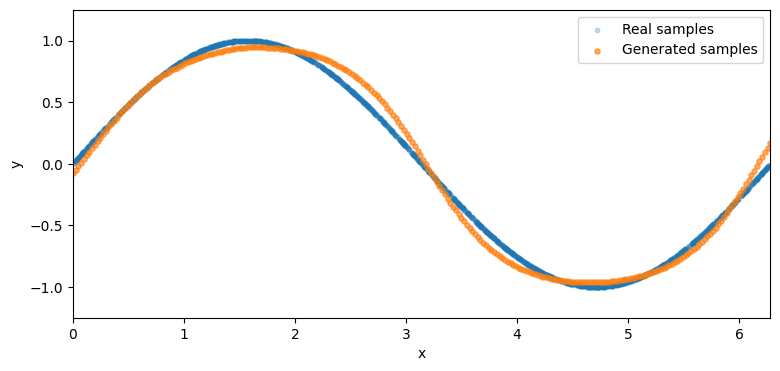

Final sine MAE: 0.0520


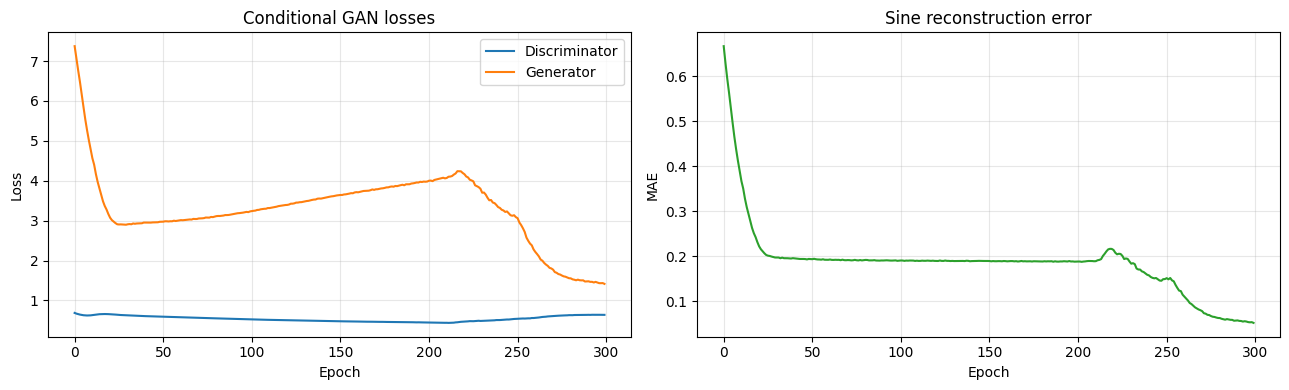

In [10]:
generated_sine_samples = sample_sine_generator(
    sine_generator, fixed_sine_x, fixed_sine_noise
)
plot_sine_distribution(sine_samples, generated_sine_samples)
print(
    f'Final sine MAE: '
    f'{sine_history["mean_absolute_error"][-1]:.4f}'
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(sine_history['discriminator_loss'], label='Discriminator')
axes[0].plot(sine_history['generator_loss'], label='Generator')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Conditional GAN losses')
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(sine_history['mean_absolute_error'], color='tab:green')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('MAE')
axes[1].set_title('Sine reconstruction error')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpreting the sine GAN

The generated points should cover the complete x-domain because the coordinate is supplied as a condition. The MAE directly measures how closely the generated y-values follow the known sine curve. The adversarial and reconstruction losses serve different purposes, so their absolute values should not be compared directly.

# 2. Generating MNIST digits with a DCGAN

A dense network discards the spatial structure of an image. We therefore use a compact **deep convolutional GAN (DCGAN)**:

- The generator expands a 100-dimensional latent vector with transposed convolutions.
- The discriminator reduces the image with strided convolutions.
- Batch normalization stabilizes the generator's intermediate feature maps.
- The discriminator has no mode-dependent normalization or dropout layers.
- A moderate batch size provides many updates per epoch, while one-sided label smoothing and a slightly lower discriminator learning rate reduce overconfidence.
- Real images and generator outputs both use the range $[-1, 1]$.

In [11]:
MNIST_BATCH_SIZE = 256 if device.type == 'cuda' else 128
NUM_WORKERS = 2 if device.type == 'cuda' else 0
PIN_MEMORY = True if device.type == 'cuda' else False
PERSISTENT_WORKERS = True if device.type == 'cuda' else False

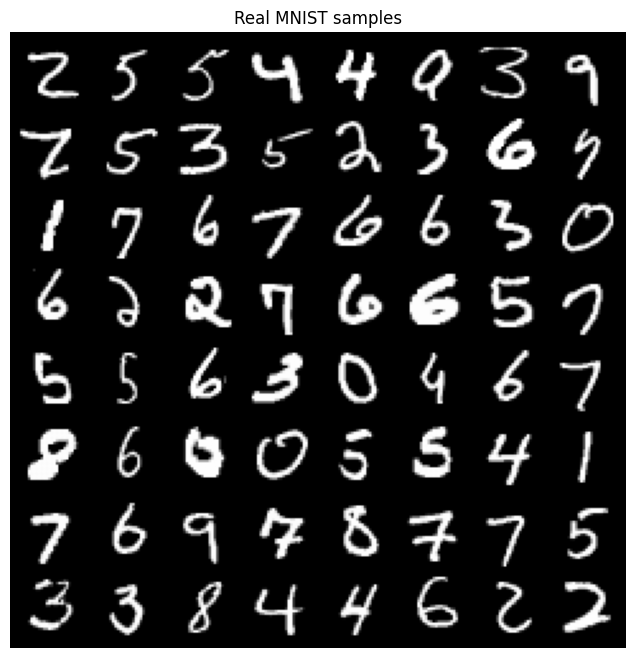

In [12]:
DATA_DIR = next(
    (parent / 'data' for parent in (Path.cwd(), *Path.cwd().parents)
     if (parent / 'data').is_dir()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError('Could not find the repository data directory.')

mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

mnist_dataset = datasets.MNIST(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=mnist_transform,
)
mnist_loader = DataLoader(
    mnist_dataset,
    batch_size=MNIST_BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=PERSISTENT_WORKERS,
)

real_images, _ = next(iter(mnist_loader))
real_grid = make_grid(
    real_images[:64], nrow=8, padding=2, normalize=True, value_range=(-1, 1)
)
plt.figure(figsize=(8, 8))
plt.imshow(real_grid.permute(1, 2, 0))
plt.axis('off')
plt.title('Real MNIST samples')
plt.show()

## DCGAN generator

The latent vector is reshaped to `N × latent_dim × 1 × 1`. Three transposed convolutions then produce images of size 7 × 7, 14 × 14, and finally 28 × 28.

In [13]:
class MNISTGenerator(nn.Module):
    def __init__(self, latent_dim=100):
        super().__init__()
        self.latent_dim = latent_dim
        self.model = nn.Sequential(
            nn.ConvTranspose2d(
                latent_dim, 128, kernel_size=7, stride=1, padding=0, bias=False
            ),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.ConvTranspose2d(
                128, 64, kernel_size=4, stride=2, padding=1, bias=False
            ),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.ConvTranspose2d(
                64, 1, kernel_size=4, stride=2, padding=1
            ),
            nn.Tanh(),
        )

    def forward(self, noise):
        noise = noise.view(noise.size(0), self.latent_dim, 1, 1)
        return self.model(noise)

## DCGAN discriminator

The discriminator reverses this process with strided convolutions and returns one logit per image. It deliberately has no batch normalization, dropout, or sigmoid. Keeping it free of mode-dependent layers lets us freeze its parameters during the generator update without changing its behavior.

In [14]:
class MNISTDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(
                1, 64, kernel_size=4, stride=2, padding=1, bias=False
            ),
            nn.LeakyReLU(0.2),
            nn.Conv2d(
                64, 128, kernel_size=4, stride=2, padding=1, bias=False
            ),
            nn.LeakyReLU(0.2),
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),
        )

    def forward(self, images):
        return self.model(images)

In [15]:
def initialize_dcgan_weights(module):
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, mean=0.0, std=0.02)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, mean=1.0, std=0.02)
        nn.init.zeros_(module.bias)

In [16]:
MNIST_LATENT_DIM = 100
MNIST_EPOCHS = 25
MNIST_LEARNING_RATE_G = 2e-4
MNIST_LEARNING_RATE_D = 1e-4

mnist_generator = MNISTGenerator(MNIST_LATENT_DIM).to(device)
mnist_discriminator = MNISTDiscriminator().to(device)
mnist_generator.apply(initialize_dcgan_weights)
mnist_discriminator.apply(initialize_dcgan_weights)

mnist_loss_fn = nn.BCEWithLogitsLoss()
mnist_optimizer_g = torch.optim.Adam(
    mnist_generator.parameters(),
    lr=MNIST_LEARNING_RATE_G,
    betas=(0.5, 0.999),
)
mnist_optimizer_d = torch.optim.Adam(
    mnist_discriminator.parameters(),
    lr=MNIST_LEARNING_RATE_D,
    betas=(0.5, 0.999),
)

fixed_mnist_noise = torch.randn(
    64, MNIST_LATENT_DIM, device=device
)

In [17]:
def generated_image_grid(generator, noise, nrow=8):
    was_training = generator.training
    generator.eval()
    with torch.inference_mode():
        generated_images = generator(noise).cpu()
    generator.train(was_training)
    return make_grid(
        generated_images,
        nrow=nrow,
        padding=2,
        normalize=True,
        value_range=(-1, 1),
    )


def show_image_grid(grid, title):
    plt.figure(figsize=(8, 8))
    plt.imshow(grid.permute(1, 2, 0))
    plt.axis('off')
    plt.title(title)
    plt.show()

In [18]:
def train_mnist_gan(
    generator, discriminator, data_loader, loss_fn,
    optimizer_g, optimizer_d, epochs, latent_dim, fixed_noise
):
    history = {
        'generator_loss': [],
        'discriminator_loss': [],
        'd_real': [],
        'd_fake': [],
    }
    snapshots = [(0, generated_image_grid(generator, fixed_noise))]

    for epoch in tqdm(range(epochs), desc='MNIST GAN epochs'):
        generator.train()
        discriminator.train()
        generator_loss_total = 0.0
        discriminator_loss_total = 0.0
        d_real_total = 0.0
        d_fake_total = 0.0

        for real_images, _ in data_loader:
            real_images = real_images.to(device)
            batch_size = real_images.size(0)
            real_targets = torch.full(
                (batch_size, 1), 0.9, device=device
            )
            fake_targets = torch.zeros((batch_size, 1), device=device)

            # Train the discriminator.
            set_requires_grad(discriminator, True)
            optimizer_d.zero_grad(set_to_none=True)

            real_logits = discriminator(real_images)
            noise = torch.randn(batch_size, latent_dim, device=device)
            fake_images = generator(noise)
            fake_logits = discriminator(fake_images.detach())

            discriminator_loss = 0.5 * (
                loss_fn(real_logits, real_targets)
                + loss_fn(fake_logits, fake_targets)
            )
            discriminator_loss.backward()
            optimizer_d.step()

            # Freeze discriminator parameters but keep one consistent mode.
            set_requires_grad(discriminator, False)
            optimizer_g.zero_grad(set_to_none=True)
            fresh_noise = torch.randn(
                batch_size, latent_dim, device=device
            )
            generated_images = generator(fresh_noise)
            generated_logits = discriminator(generated_images)
            generator_loss = loss_fn(
                generated_logits, torch.ones_like(generated_logits)
            )
            generator_loss.backward()
            optimizer_g.step()

            generator_loss_total += generator_loss.item()
            discriminator_loss_total += discriminator_loss.item()
            d_real_total += torch.sigmoid(real_logits).mean().item()
            d_fake_total += torch.sigmoid(fake_logits).mean().item()

        set_requires_grad(discriminator, True)
        number_of_batches = len(data_loader)
        history['generator_loss'].append(
            generator_loss_total / number_of_batches
        )
        history['discriminator_loss'].append(
            discriminator_loss_total / number_of_batches
        )
        history['d_real'].append(d_real_total / number_of_batches)
        history['d_fake'].append(d_fake_total / number_of_batches)

        snapshots.append((
            epoch + 1, generated_image_grid(generator, fixed_noise)
        ))
        print(
            f'Epoch {epoch + 1:02d}/{epochs}: '
            f'D loss={history["discriminator_loss"][-1]:.4f}, '
            f'G loss={history["generator_loss"][-1]:.4f}, '
            f'D(x)={history["d_real"][-1]:.3f}, '
            f'D(G(z))={history["d_fake"][-1]:.3f}'
        )

    return history, snapshots

In [19]:
mnist_history, mnist_snapshots = train_mnist_gan(
    mnist_generator,
    mnist_discriminator,
    mnist_loader,
    mnist_loss_fn,
    mnist_optimizer_g,
    mnist_optimizer_d,
    MNIST_EPOCHS,
    MNIST_LATENT_DIM,
    fixed_mnist_noise,
)

save_gan_checkpoint(
    'mnist_dcgan_pytorch.pt',
    mnist_generator,
    mnist_discriminator,
    mnist_history,
    {
        'latent_dim': MNIST_LATENT_DIM,
        'epochs': MNIST_EPOCHS,
        'seed': SEED,
    },
)

MNIST GAN epochs:   0%|          | 0/25 [00:00<?, ?it/s]

Epoch 01/25: D loss=0.6718, G loss=0.6488, D(x)=0.575, D(G(z))=0.531
Epoch 02/25: D loss=0.6832, G loss=0.6901, D(x)=0.517, D(G(z))=0.503
Epoch 03/25: D loss=0.6749, G loss=0.7422, D(x)=0.499, D(G(z))=0.480
Epoch 04/25: D loss=0.6666, G loss=0.8168, D(x)=0.478, D(G(z))=0.451
Epoch 05/25: D loss=0.6656, G loss=0.8373, D(x)=0.467, D(G(z))=0.439
Epoch 06/25: D loss=0.6677, G loss=0.8377, D(x)=0.465, D(G(z))=0.439
Epoch 07/25: D loss=0.6720, G loss=0.8329, D(x)=0.461, D(G(z))=0.440
Epoch 08/25: D loss=0.6755, G loss=0.8203, D(x)=0.459, D(G(z))=0.443
Epoch 09/25: D loss=0.6762, G loss=0.8179, D(x)=0.459, D(G(z))=0.444
Epoch 10/25: D loss=0.6772, G loss=0.8204, D(x)=0.458, D(G(z))=0.444
Epoch 11/25: D loss=0.6771, G loss=0.8186, D(x)=0.458, D(G(z))=0.444
Epoch 12/25: D loss=0.6774, G loss=0.8280, D(x)=0.458, D(G(z))=0.444
Epoch 13/25: D loss=0.6764, G loss=0.8269, D(x)=0.459, D(G(z))=0.443
Epoch 14/25: D loss=0.6755, G loss=0.8300, D(x)=0.460, D(G(z))=0.442
Epoch 15/25: D loss=0.6745, G loss

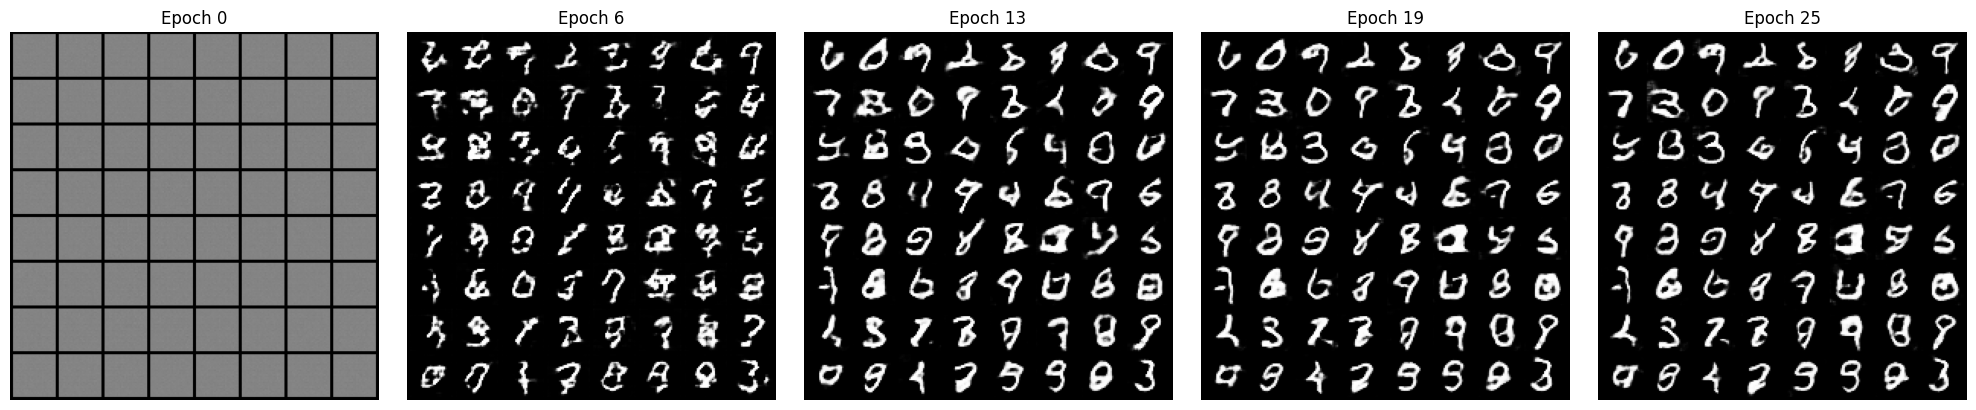

In [20]:
snapshot_indices = sorted(set([
    0,
    len(mnist_snapshots) // 4,
    len(mnist_snapshots) // 2,
    3 * len(mnist_snapshots) // 4,
    len(mnist_snapshots) - 1,
]))

fig, axes = plt.subplots(
    1, len(snapshot_indices), figsize=(4 * len(snapshot_indices), 4)
)
if len(snapshot_indices) == 1:
    axes = [axes]

for axis, snapshot_index in zip(axes, snapshot_indices):
    epoch, grid = mnist_snapshots[snapshot_index]
    axis.imshow(grid.permute(1, 2, 0))
    axis.set_title(f'Epoch {epoch}')
    axis.axis('off')

plt.tight_layout()
plt.show()

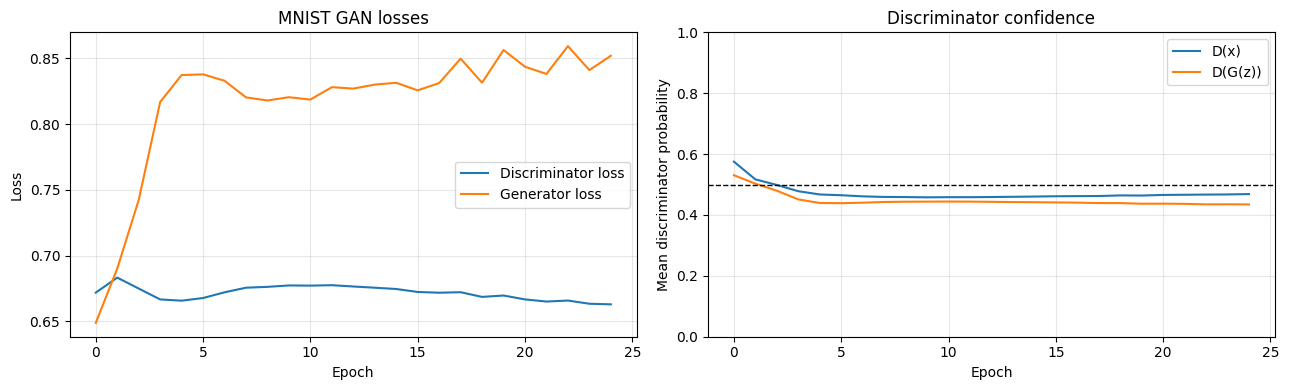

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(
    mnist_history['discriminator_loss'], label='Discriminator loss'
)
axes[0].plot(mnist_history['generator_loss'], label='Generator loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('MNIST GAN losses')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(mnist_history['d_real'], label='D(x)')
axes[1].plot(mnist_history['d_fake'], label='D(G(z))')
axes[1].axhline(0.5, color='black', linestyle='--', linewidth=1)
axes[1].set_ylim(0, 1)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Mean discriminator probability')
axes[1].set_title('Discriminator confidence')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

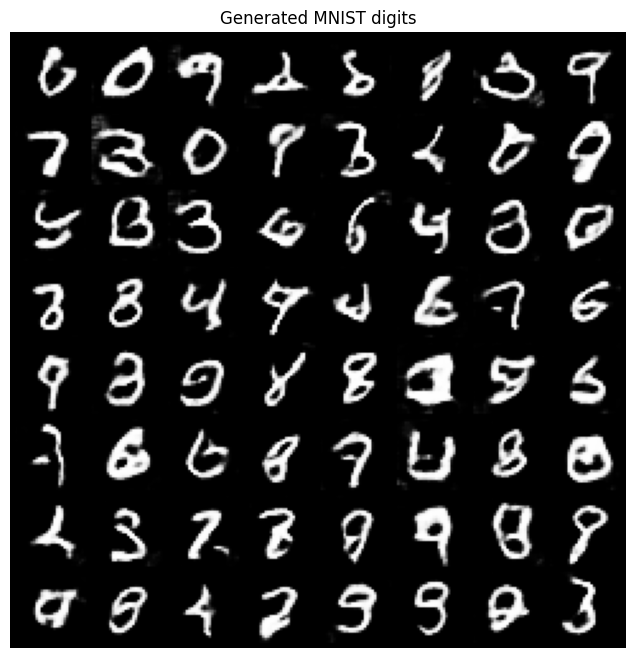

In [22]:
final_grid = generated_image_grid(
    mnist_generator, fixed_mnist_noise
)
show_image_grid(final_grid, 'Generated MNIST digits')

## Interpreting GAN training

GAN losses do not behave like the loss of a conventional classifier. Neither network should simply drive its own loss to zero while the other diverges. Generated samples from a **fixed** latent batch are the most useful qualitative check because they reveal progress, mode collapse, and lack of diversity.

`D(x)` is the discriminator's mean estimated probability for real images and `D(G(z))` is its mean estimated probability for generated images. Values near 0.5 can occur around an equilibrium, but 0.5 alone does not prove that the generated images are good.

## **TASK: Explore the training behavior**

1. Change the latent dimension, learning rate, batch size, or number of epochs. Compare image quality and stability.
2. Change the number of generator and discriminator feature maps. What happens if one network becomes much stronger than the other?
3. Observe the fixed-noise snapshots. Do all latent vectors generate different digits, or is there evidence of mode collapse?
4. Compare the loss curves with the generated samples. Explain why a low generator loss or discriminator accuracy near 50% is not sufficient evidence of a successful GAN.
5. Replace the smoothed real target 0.9 with 1.0 and compare stability and image quality.